# 02. Ridge regression

We predict the final numerical grade (`course_numeric_grade`) from Moodle activity in the first 8 weeks of the semester. We use a regularised linear regression (Ridge), train it on the earlier years and test it on 2025 and 2026.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error

## 1. Load the shared train/test split

In [2]:
train = pd.read_csv("shared_train.csv")
test = pd.read_csv("shared_test.csv")

print("train:", train.shape, " test:", test.shape)
print("train years:", sorted(train["year"].unique()))
print("test years:", sorted(test["year"].unique()))
train.head()

train: (551, 7)  test: (279, 7)
train years: [np.int64(2019), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
test years: [np.int64(2025), np.int64(2026)]


,year,actor_id,course_numeric_grade,total_events,active_days,course_module_views,course_views
0,2019,S027cf9,72.10,132,18,20,34
1,2019,S032255,67.70,48,6,18,8
2,2019,S03a8b8,107.02,221,30,39,75
3,2019,S04cf7f,85.85,161,20,26,38
4,2019,S05f285,37.15,456,32,76,177


## 2. Predictors and target

In [3]:
FEATURES = ["total_events", "active_days", "course_module_views", "course_views"]
TARGET = "course_numeric_grade"

X_train = train[FEATURES]
y_train = train[TARGET]
groups = train["year"]  # year of each training row (used later)

X_test_2025 = test.loc[test["year"] == 2025, FEATURES]
y_test_2025 = test.loc[test["year"] == 2025, TARGET]
X_test_2026 = test.loc[test["year"] == 2026, FEATURES]
y_test_2026 = test.loc[test["year"] == 2026, TARGET]

print(len(X_train), len(X_test_2025), len(X_test_2026))

551 137 142


## 3. Pipeline: standardisation + Ridge

The features have very different scales (for example active_days is about 0-50 and total_events can be in hundreds), so we standardise them. Ridge adds a penalty for large coefficients, which reduces overfitting.

In [4]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


## 4 and 5. Train and choose alpha using only the training data

The parameter `alpha` is the strength of the regularisation. We try several values. To choose one, we use "leave one year out" validation inside the training years: the model is trained on four training years and checked on the fifth. The test years 2025 and 2026 are not used.

In [5]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]

grid = GridSearchCV(
    pipe,
    param_grid={"ridge__alpha": alphas},
    cv=LeaveOneGroupOut(),
    scoring="neg_mean_absolute_error",
)
grid.fit(X_train, y_train, groups=groups)

cv_results = pd.DataFrame({
    "alpha": alphas,
    "cv_MAE": -grid.cv_results_["mean_test_score"],
}).round(2)
print(cv_results)

best_alpha = grid.best_params_["ridge__alpha"]
print("best alpha:", best_alpha)

     alpha  cv_MAE
0     0.01   17.39
1     0.10   17.39
2     1.00   17.39
3    10.00   17.40
4   100.00   17.53
5  1000.00   17.91
best alpha: 1


In [6]:
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha)),
])
final_model.fit(X_train, y_train)

coefs = pd.Series(final_model.named_steps["ridge"].coef_, index=FEATURES).round(2)
print(coefs)

total_events            1.48
active_days            11.62
course_module_views     2.35
course_views           -5.81
dtype: float64


## 6. Predictions for 2025 and 2026 separately

In [7]:
pred_2025 = final_model.predict(X_test_2025)
pred_2026 = final_model.predict(X_test_2026)

print(pred_2025[:5].round(1))
print(pred_2026[:5].round(1))

[69.4 68.6 79.1 58.2 44.2]
[61.  47.4 55.7 57.7 67.7]


## 7. MAE and comparison with the baseline

MAE (mean absolute error) is the average difference between the real and the predicted grade, in grade points. The baseline always predicts the average grade of the training years.

In [8]:
baseline_value = y_train.mean()

results = pd.DataFrame({
    "year": [2025, 2026],
    "students": [len(y_test_2025), len(y_test_2026)],
    "MAE_ridge": [
        mean_absolute_error(y_test_2025, pred_2025),
        mean_absolute_error(y_test_2026, pred_2026),
    ],
    "MAE_baseline": [
        mean_absolute_error(y_test_2025, np.full(len(y_test_2025), baseline_value)),
        mean_absolute_error(y_test_2026, np.full(len(y_test_2026), baseline_value)),
    ],
}).round(2)

results["improvement"] = (results["MAE_baseline"] - results["MAE_ridge"]).round(2)

print("baseline (mean training grade):", round(baseline_value, 2))
results.to_csv("ridge_results.csv", index=False)
results

baseline (mean training grade): 66.93


,year,students,MAE_ridge,MAE_baseline,improvement
0,2025,137,18.34,20.21,1.87
1,2026,142,19.53,21.02,1.49


## 8. Actual vs predicted grades

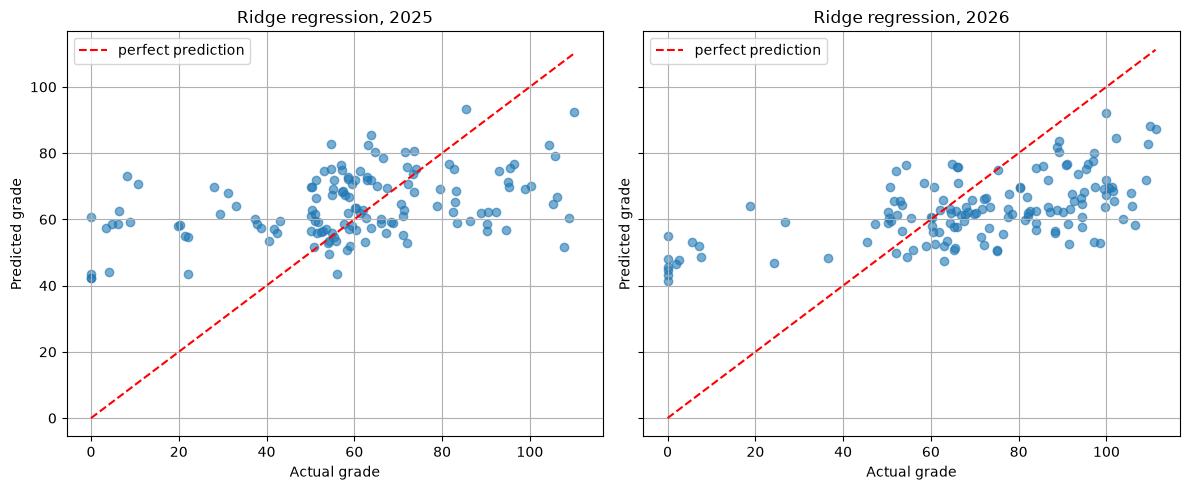

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, year, y_true, y_pred in [
    (axes[0], 2025, y_test_2025, pred_2025),
    (axes[1], 2026, y_test_2026, pred_2026),
]:
    ax.scatter(y_true, y_pred, alpha=0.6)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, color="red", linestyle="--", label="perfect prediction")
    ax.set_title(f"Ridge regression, {year}")
    ax.set_xlabel("Actual grade")
    ax.set_ylabel("Predicted grade")
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.savefig("ridge_predictions.png", dpi=150)
plt.show()

## 9. Explanation

We predicted the final grade from four Moodle activity features of the first 8 weeks (total events, active days, course module views and course views) with a Ridge regression (alpha = 1, chosen on the training years only). On the test years the mean absolute error is 18.34 grade points in 2025 and 19.53 in 2026. The baseline, which always predicts the average training grade (66.93), has an error of 20.21 and 21.02. So the model is better than the baseline, but only by 1.87 and 1.49 points (about 7-9%). Moodle activity on the first 8 weeks gives only a little information about the final grade.

The scatter plots show the same. The predicted grades stay in a narrow range (about 40-90), while the real grades go from 0 to about 110. The points are far from the red line: students with very low real grades (close to 0) get predictions of about 40–60, and students with the highest grades get lower predictions than they really have. The model mostly predicts values close to the average. The strongest feature is active_days: students who were active on more different days have higher predicted grades. The coefficient of course_views is negative, but the features are correlated with each other, so the coefficients should not be read as separate effects.

Limitations:
- We use only four simple activity features and only the first 8 weeks. Final grades also depend on things that Moodle does not show, for example previous knowledge or work outside Moodle.
- Ridge is a linear model, so it cannot find more complex patterns.
- Student activity was lower in 2025-2026 than in many earlier years, so a model trained on earlier years may fit the later years less well.
- According to the dataset description, grading in 2019 was different from later years, which may add noise to the training data.
- The test sets are small (137 and 142 students), so the results can change a lot if a few students are different.
- Students without a final grade are not in the data, so we do not know how the model works for them.